# Integrative Project

## US015 - "Statistical analysis of the average annual profit of a user-specified railway station."

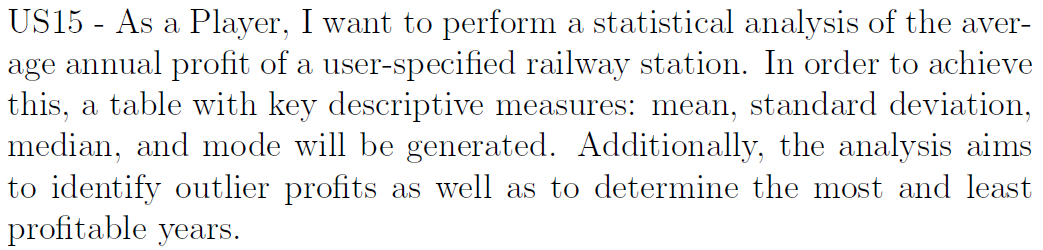

## *User Story Details:*
As a Player, I want to perform a statistical analysis of the average annual profit of a user-specified railway station. In order to achieve this, a table with key descriptive measures: mean, standard deviation, median, and mode will be generated. Additionally, the analysis aims to identify outlier profits as well as to determine the most and least profitable years.

### *Theoretical Explanation*

### What is a 'Mean'?
In mathematics, the mean, also known as arithmetic mean (or average), is calculated by summing all the numbers in a set and then dividing by the total number of values in that set. This results in a single value that represents the central tendency of the data.

Formula: Mean (μ) = Σx / n


### What is a standard deviation?
In mathematics and statistics, standard deviation is a measure of the dispersion or spread of a dataset. It quantifies how much individual data points deviate from the mean (average) value of the dataset. A low standard deviation indicates data points are clustered tightly around the mean, while a high standard deviation suggests the data is more spread out.

Formula: Standard Deviation (σ) = √(Σ(x - μ)² / (n-1))

### What is a 'Median'?
In mathematics, the median is the middle value in a sorted list of numbers. It represents the point where half of the values are below and half are above. For a set with an odd number of values, the median is simply the middle number. For a set with an even number of values, it's the average of the two middle numbers.

Formula: Median = middle value when data is sorted


### What is a 'Mode'?
The mode is the most common number that appears in your set of data. To find the mode count how often each number appears and the number that appears the most times is the mode.

### What is an 'Outlier'?
In mathematics, an outlier is a data point that significantly deviates from the rest of the data points in a set. It can be either much larger or much smaller than the other values, essentially lying outside the typical pattern of the distribution.

Formula: Q1 = 25th percentile, Q3 = 75th percentile
Formula: IQR = Q3 - Q1
Formula: Lower bound = Q1 - 1.5 × IQR
Formula: Upper bound = Q3 + 1.5 × IQR


In [ ]:
import pandas as pd
import numpy as np

# Load data
df = pd.read_csv('Stations_Data.csv', sep=';')

# Display available stations and cargo types for user selection
print("="*60)
print("RAILWAY STATION PROFIT ANALYSIS SYSTEM")
print("="*60)

# Show available stations
available_stations = df['Station'].unique()
print(f"\nAvailable Stations ({len(available_stations)}):")
print("-" * 40)
for i, station in enumerate(sorted(available_stations), 1):
    print(f"{i:2d}. {station}")

# Show available cargo types from the dataset
cargo_types = ['Iron', 'Coal', 'Steel', 'Vegetables', 'Cereals', 'Wool', 'Coffee', 'Cattle']
transport_types = ['Passengers', 'Mail']
print(f"\nAvailable Cargo Types ({len(cargo_types)}):")
print("-" * 40)
for i, cargo in enumerate(cargo_types, 1):
    print(f"{i:2d}. {cargo}")

print(f"\nOther Transport Categories ({len(transport_types)}):")
print("-" * 40)
for i, transport in enumerate(transport_types, 1):
    print(f"{i:2d}. {transport}")

print("\n" + "="*60)

# Organize the document info in two columns
num_cols = ['Revenues', 'Expenses']

# Convert values to either string or NaN if they're not numeric
# Formula: Replace comma decimal separators with dots for proper numeric conversion
for col in num_cols:
    df[col] = pd.to_numeric(df[col].astype(str).str.replace(',','.',regex=False), errors='coerce')

# Calculate the profit by calculating the difference between the revenues and expenses
# Formula: Profit = Revenues - Expenses
df['Profit'] = df['Revenues'] - df['Expenses']

# Group by station and year and calculate the sum for each station in each year
# This aggregates monthly/quarterly data into annual totals
annual_profit = (df.groupby(['Station', 'Year'], as_index=False)['Profit'].sum())

# Input - station selection
station = input("Insert the station's name: ").strip()

print("="*60)

# Show the profit for that station alone
station_data = annual_profit[annual_profit['Station'] == station]

# Check if data was found
if station_data.empty:
    print(f"No data found for station '{station}'.")
else:
    # If it is, it creates a column for profits and another for the years of the chosen station
    profits = station_data['Profit']
    years = station_data['Year']

    # Calculate descriptive statistics
    # Formula: Mean (μ) = Σx / n
    mean = profits.mean()

    # Formula: Standard Deviation (σ) = √(Σ(x - μ)² / (n-1))
    std = profits.std()

    # Formula: Median = middle value when data is sorted
    median = profits.median()

    # Mode can return multiple values if they're repeated
    # Mode = most frequently occurring value(s)
    mode = profits.mode().iloc[0] if not profits.mode().empty else None

    print(f"\nDescriptive measures for station: '{station}':")
    print(f"Mean: {mean:.2f}")
    print(f"Standard deviation: {std:.2f}")
    print(f"Median: {median:.2f}")
    print(f"Mode: {mode:.2f}")

    # Find outliers using IQR (Interquartile Range) method
    # Formula: Q1 = 25th percentile, Q3 = 75th percentile
    Q1 = profits.quantile(0.25)  # 1st quartile
    Q3 = profits.quantile(0.75)  # 3rd quartile

    # Formula: IQR = Q3 - Q1
    IQR = Q3 - Q1  # Calculate the range between quartiles

    # Formula: Lower bound = Q1 - 1.5 × IQR
    lower = Q1 - 1.5 * IQR  # Calculate the inferior limit

    # Formula: Upper bound = Q3 + 1.5 × IQR
    upper = Q3 + 1.5 * IQR  # Calculate the superior limit

    # Only keep the lines outside the lower and upper limits (outliers)
    outliers = station_data[(station_data['Profit'] < lower) | (station_data['Profit'] > upper)]

    print(f"\nFound outliers ({len(outliers)}):")
    if not outliers.empty:
        # Convert to string for display
        print(outliers[['Year', 'Profit']].to_string(index=False))
    else:
        print("No outliers found.")

    # Most and least profitable years
    # Calculate the biggest and lowest index
    max_row = station_data.loc[profits.idxmax()]
    min_row = station_data.loc[profits.idxmin()]

    # Print the complete line for each profitable year
    print(f"\nMost profitable year: {int(max_row['Year'])} -> {max_row['Profit']:.2f}")
    print(f"Least profitable year: {int(min_row['Year'])} -> {min_row['Profit']:.2f}")

    # COMPREHENSIVE RESULTS ANALYSIS AND CONCLUSIONS
    print("\n" + "="*80)
    print("COMPREHENSIVE STATISTICAL ANALYSIS - RESULTS AND CONCLUSIONS")
    print("="*80)

    # Data Overview
    print(f"\n1. DATA OVERVIEW:")
    print(f"   • Station analyzed: {station}")
    print(f"   • Analysis period: {int(years.min())} - {int(years.max())} ({len(years)} years)")
    print(f"   • Total profit over period: €{profits.sum():,.2f}")

    # Central Tendency Analysis
    print(f"\n2. CENTRAL TENDENCY MEASURES:")
    print(f"   • Mean (Average): {mean:,.2f}€")
    print(f"     → This represents the typical annual profit expectation")
    print(f"   • Median: {median:,.2f}€")
    print(f"     → 50% of years had profits above/below this value")
    if mode is not None:
        print(f"   • Mode: {mode:,.2f}€")
        print(f"     → Most frequently occurring profit value")

    # Variability Analysis
    print(f"\n3. VARIABILITY AND RISK ASSESSMENT:")
    print(f"   • Standard Deviation: {std:,.2f}€")
    print(f"   • Coefficient of Variation: {(std/abs(mean)*100):.1f}%")
    if (std/abs(mean)*100) < 15:
        volatility = "LOW - Stable profit pattern"
    elif (std/abs(mean)*100) < 30:
        volatility = "MODERATE - Acceptable profit variation"
    else:
        volatility = "HIGH - Volatile profit pattern"
    print(f"   • Risk Level: {volatility}")

    # Quartile Analysis
    print(f"\n4. QUARTILE DISTRIBUTION:")
    print(f"   • Q1 (25th percentile): {Q1:,.2f}€")
    print(f"   • Q2 (50th percentile/Median): {median:,.2f}€")
    print(f"   • Q3 (75th percentile): {Q3:,.2f}€")
    print(f"   • Interquartile Range (IQR): {IQR:,.2f}€")

    # Performance Analysis
    print(f"\n5. PERFORMANCE HIGHLIGHTS:")
    profit_range = profits.max() - profits.min()
    print(f"   • Profit Range: €{profit_range:,.2f}")
    print(f"   • Best Performance: {int(max_row['Year'])} ({max_row['Profit']:,.2f}€)")
    print(f"   • Worst Performance: {int(min_row['Year'])} ({min_row['Profit']:,.2f}€)")

    # Profitability Assessment
    profitable_years = len(profits[profits > 0])
    loss_years = len(profits[profits < 0])
    print(f"   • Profitable Years: {profitable_years} out of {len(profits)} ({profitable_years/len(profits)*100:.1f}%)")
    if loss_years > 0:
        print(f"   • Loss Years: {loss_years} ({loss_years/len(profits)*100:.1f}%)")

    # Outlier Analysis
    print(f"\n6. OUTLIER ANALYSIS:")
    print(f"   • Outlier Detection Method: IQR Method (1.5 × IQR rule)")
    print(f"   • Outlier Boundaries: {lower:,.2f}€ to {upper:,.2f}€")
    print(f"   • Number of Outliers: {len(outliers)} ({len(outliers)/len(profits)*100:.1f}% of data)")
    if not outliers.empty:
        print(f"   • Outlier Impact: These years show exceptional performance (positive or negative)")

    # Statistical Insights
    print(f"\n7. STATISTICAL INSIGHTS:")

    # Skewness analysis
    skewness = profits.skew()
    if skewness > 0.5:
        skew_interpretation = "Positively skewed - More years with below-average profits"
    elif skewness < -0.5:
        skew_interpretation = "Negatively skewed - More years with above-average profits"
    else:
        skew_interpretation = "Approximately symmetric distribution"
    print(f"   • Distribution Shape: {skew_interpretation}")

    # Mean vs Median comparison
    if abs(mean - median) / std < 0.2:
        distribution_type = "Normal-like distribution"
    else:
        distribution_type = "Skewed distribution"
    print(f"   • Distribution Type: {distribution_type}")

    # Trend analysis (simple)
    if len(profits) >= 3:
        recent_years = profits.tail(3).mean()
        early_years = profits.head(3).mean()
        if recent_years > early_years * 1.1:
            trend = "IMPROVING - Recent years show better performance"
        elif recent_years < early_years * 0.9:
            trend = "DECLINING - Recent years show worse performance"
        else:
            trend = "STABLE - No clear upward or downward trend"
        print(f"   • Long-term Trend: {trend}")

## US016 - "Comparative analysis of passenger arrivals across all stations."

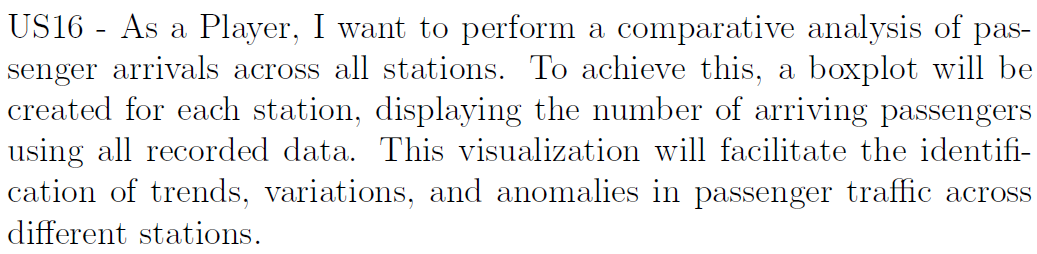

## *User Story Details:*
As a Player, I want to perform a comparative analysis of passenger arrivals across all stations. To achieve this, a boxplot will be created for each station, displaying the number of arriving passengers using all recorded data. This visualization will facilitate the identification of trends, variations, and anomalies in passenger traffic across different stations.

### *Theoretical Explanation*

### What is a boxplot?
A boxplot, also known as a box-and-whisker plot, is a standardized graphical representation of data distribution. It displays the dataset’s minimum, first quartile (Q1), median (Q2), third quartile (Q3), and maximum values. It also highlights potential outliers, providing a clear summary of the central tendency and variability in the data.

### What is the 'median' line in a boxplot?
The line inside the box represents the median of the dataset, which divides the data into two equal halves. It indicates the central value, giving insight into the balance point of the data.

### What do the 'whiskers' represent?
 The whiskers in a boxplot extend to the smallest and largest values within 1.5 times the interquartile range (IQR) from the lower and upper quartiles, respectively. They show the spread of most of the data, excluding outliers.

### What are 'outliers' in a boxplot?
Outliers are data points that fall significantly outside the expected range. In a boxplot, they are plotted as individual dots beyond the whiskers. Outliers may indicate variability, data entry errors, or important anomalies worth investigating.

### What is the 'mean' marker in the boxplot?
If shown, the mean marker (in this case, a white diamond) represents the arithmetic average of the data. It complements the median by giving a sense of the overall balance of all values in the dataset.


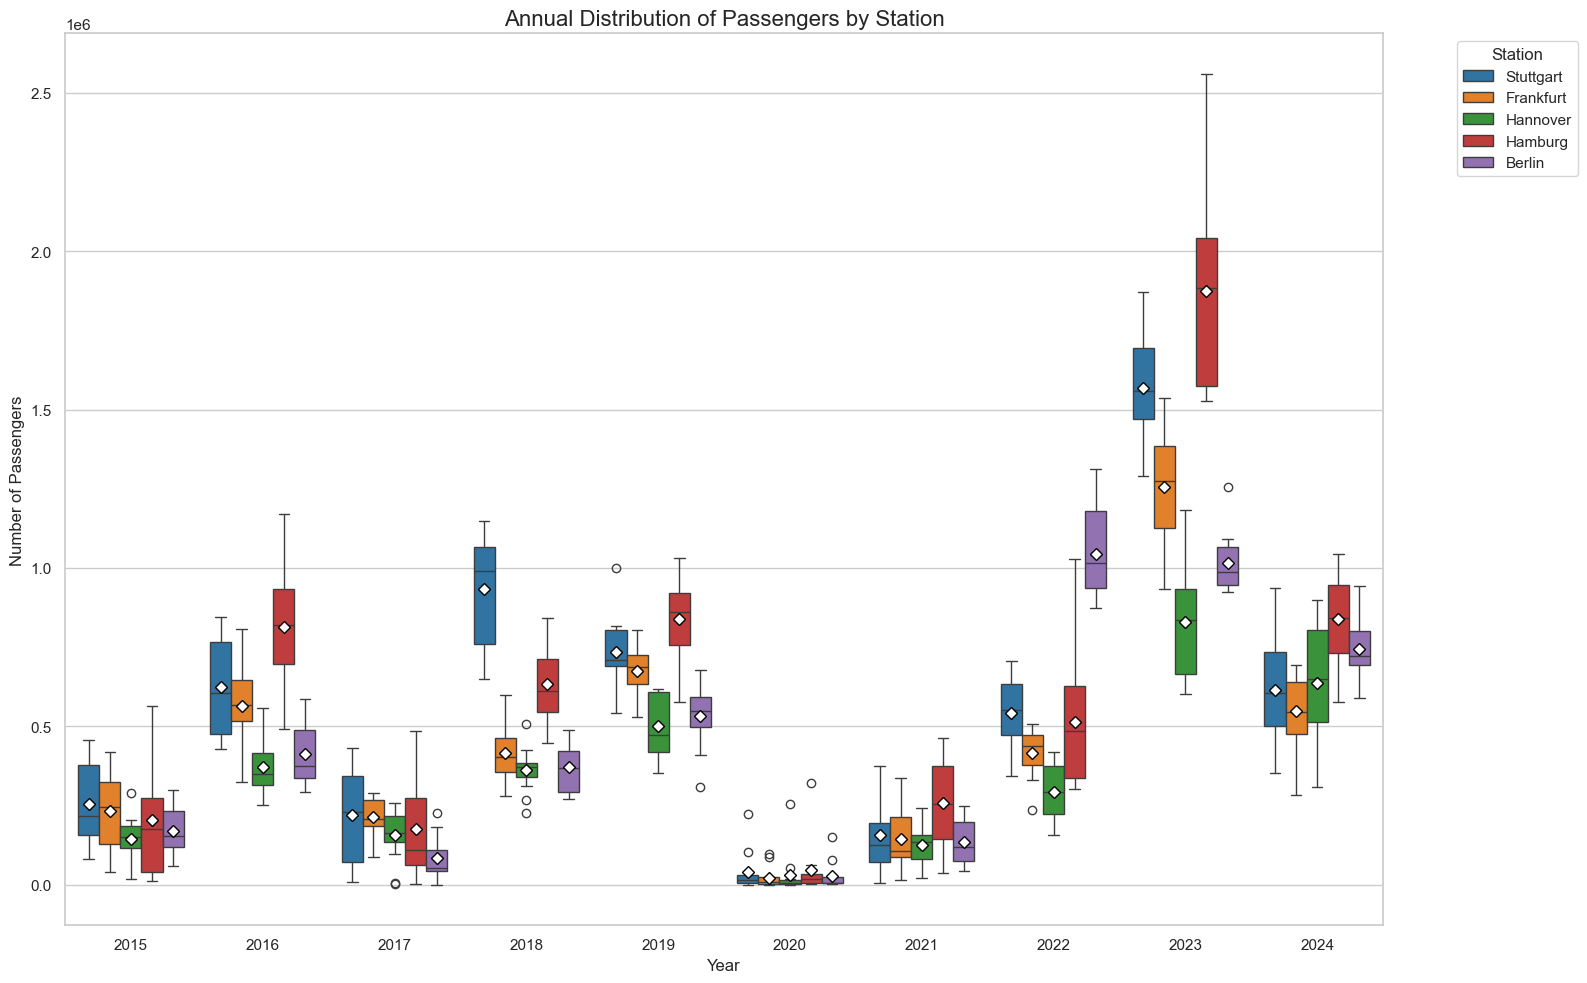

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


data = pd.read_csv('Stations_Data.csv', sep=';', decimal=',')

stations = data['Station'].unique()
palette = sns.color_palette("tab10", n_colors=len(stations)) 


sns.set(style="whitegrid")
plt.figure(figsize=(16, 10))  

sns.boxplot(
    x='Year',
    y='Passengers',
    hue='Station',
    data=data,
    palette=palette,
    showmeans=True,
    meanprops={'marker': 'D', 'markerfacecolor': 'white', 'markeredgecolor': 'black'}
)


plt.title('Annual Distribution of Passengers by Station', fontsize=16)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Number of Passengers', fontsize=12)


plt.legend(title='Station', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


### Results Interpretation

The boxplot diagram provides a comprehensive overview of passenger distribution across key railway stations over the years. It highlights not only volume disparities between stations but also reveals temporal trends and anomalies that are crucial for infrastructure planning and operational strategy.

## Pandemic Impact and Recovery
A pronounced drop in passenger activity during 2020 and 2021 is clearly visible across all stations. This aligns with the global COVID-19 pandemic, which significantly disrupted travel and public transportation. This period of underutilization draws attention to:

The vulnerability of centralized transport systems to global crises.

The need for contingency planning and adaptable infrastructure in future disruptions.

## Post-2022 Surge
From 2022 onward, there is a remarkable increase in passenger volume:

Stuttgart and Berlin emerge as dominant hubs, handling the largest flows of passengers.

This resurgence indicates both a return to normality and possible urban growth or policy-driven investments in these cities.

The intensity of recovery also suggests where maintenance backlogs or capacity bottlenecks might arise.

## Variability & Planning Challenges
Stations like Frankfurt and Hamburg exhibit high interquartile ranges and outliers, signaling:

Unpredictable demand patterns.

The necessity for scalable solutions such as modular station upgrades or dynamic scheduling.

## Strategic Implications for the Player
Capacity upgrades should be prioritized in high-volume stations (e.g., Stuttgart, Berlin).

Flexible infrastructure is essential in high-variance stations (e.g., Frankfurt).

Historical trends must guide budget allocation, ensuring preparedness for unexpected demand shifts.

Lines connected to high-growth stations may require rail reinforcements or duplication.


## US017 - "Analysis of the cargo arriving at each station."

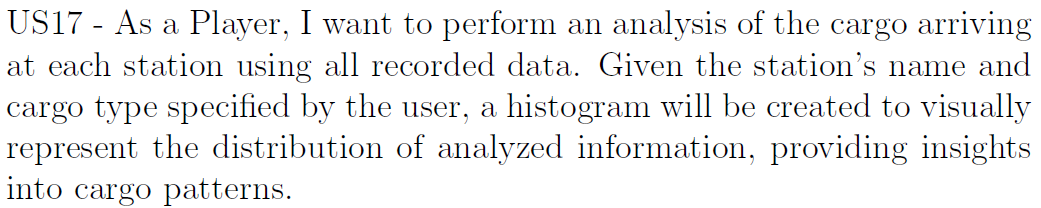

Station name:  Berlin
Cargo type:  Coal


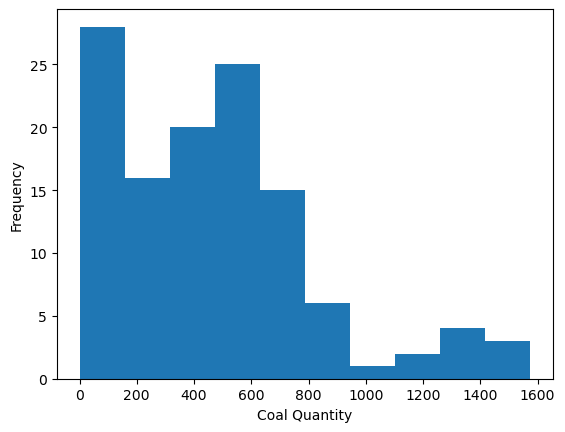

In [38]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

filePath = 'Stations_Data.csv'
data = pd.read_csv(filePath, sep=';', decimal=",")

stationName = input('Station name: ')
cargo = input('Cargo type: ')

filteredData = data[data['Station'] == stationName]

if cargo not in data.columns:
    print('Cargo type does not exist')
else:
    cargas = filteredData[cargo]
    plt.xlabel(f"{cargo} Quantity")
    plt.ylabel("Frequency")
    plt.hist(cargas)
    plt.show()


## US018 - "Analysis of train distribution, passengers and mail across different stations

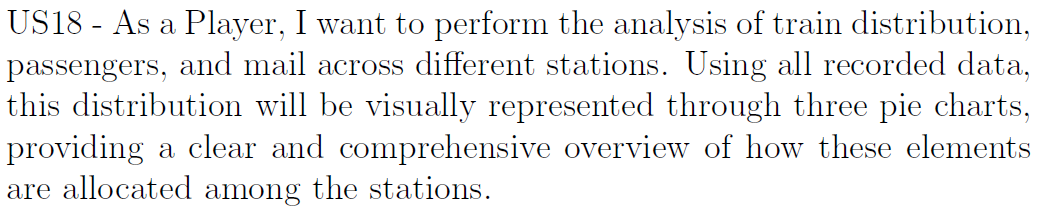

### **Theoretical Concepts**

#### What is a "Pie Chart"?
It's a data representation method, that divides a circle in different sectors which area is proportional to the category frequency each represents.

#### What is "Absolute Frequency"?
It's the number of observations associated to a specific category.

**Formula:** $$
\sum_{i=1}^{c} n_i = n
$$

#### What is "Relative Frequency"?
It's the percentage associated to a defined category, considering the total number of observations.

**Formula:** $$
f_i = \frac{n_i}{n}
$$

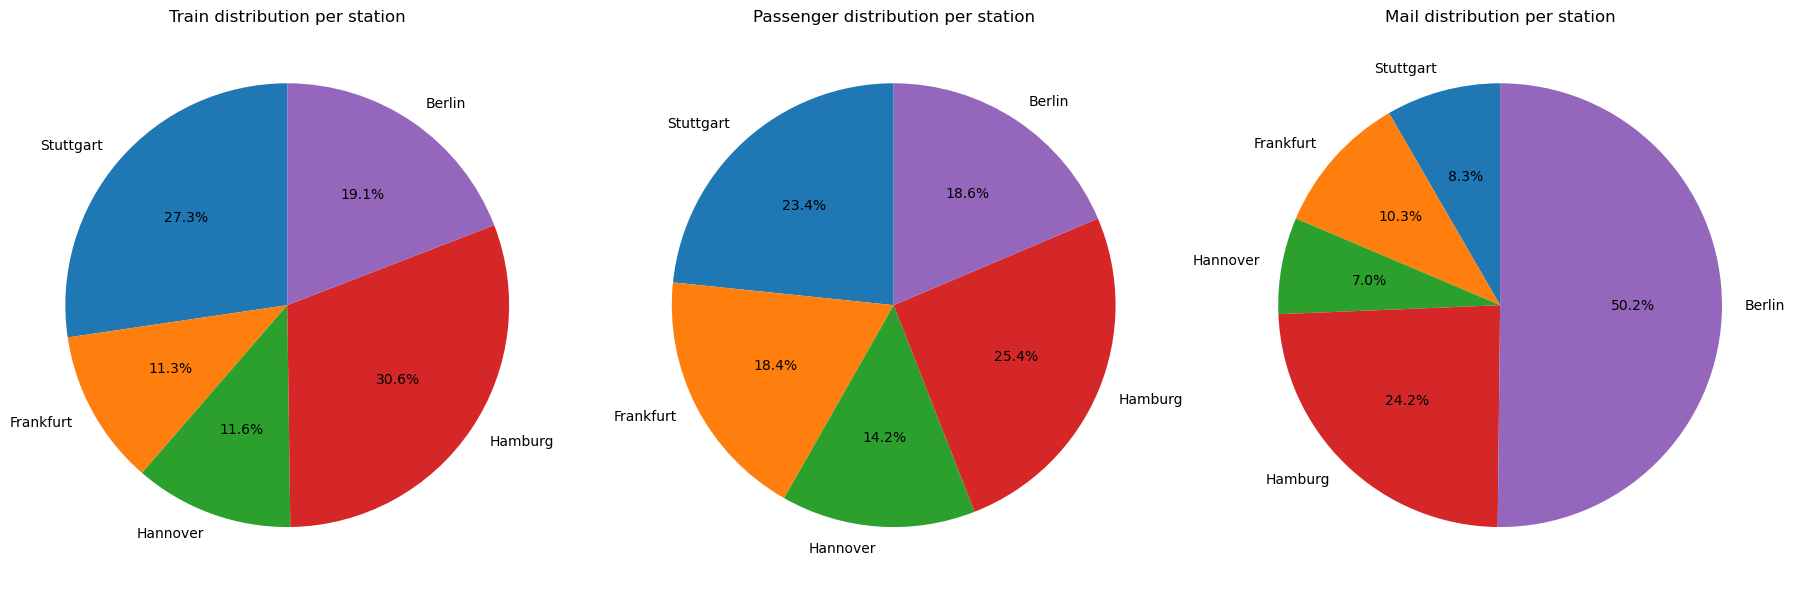

In [1]:
# List of imports
import numpy as np
from scipy import stats
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Read of File .csv with the Stations Data
filePath = 'Stations_Data.csv'
stationsData = pd.read_csv(filePath, sep=';', decimal=",")

# Calculating the total data of each attribute
trainsTotal = stationsData['Arrivals'].sum()
passengerTotal = stationsData['Passengers'].sum()
mailTotal = stationsData['Mail'].sum()

# Calculating the data per station
stationsList = stationsData['Station'].unique()

stationNames = []
trainSums = []
passengerSums = []
mailSums = []

for station in stationsList:
    stationRows = stationsData[stationsData['Station'] == station]
    trains = stationRows['Arrivals'].sum()
    passengers = stationRows['Passengers'].sum()
    mail = stationRows['Mail'].sum()

    stationNames.append(station)
    trainSums.append(trains)
    passengerSums.append(passengers)
    mailSums.append(mail)

# Calculating the percentages for each data
trainsPercentageList = []
passengersPercentageList = []
mailPercentageList = []

for i in range(len(stationNames)):
    trainsPercentage = trainSums[i] / trainsTotal
    passengerPercentage = passengerSums[i] / passengerTotal
    mailPercentage = mailSums[i] / mailTotal

    trainsPercentageList.append(trainsPercentage)
    passengersPercentageList.append(passengerPercentage)
    mailPercentageList.append(mailPercentage)

# Create a single figure with 3 subplots in one row
fig, axs = plt.subplots(1, 3, figsize=(18, 6))  # 1 row, 3 columns

# Pie chart for train distribution
axs[0].pie(trainsPercentageList, labels=stationNames, autopct='%1.1f%%', startangle=90)
axs[0].set_title('Train distribution per station')
axs[0].axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.

# Pie chart for passenger distribution
axs[1].pie(passengersPercentageList, labels=stationNames, autopct='%1.1f%%', startangle=90)
axs[1].set_title('Passenger distribution per station')
axs[1].axis('equal')

# Pie chart for mail distribution
axs[2].pie(mailPercentageList, labels=stationNames, autopct='%1.1f%%', startangle=90)
axs[2].set_title('Mail distribution per station')
axs[2].axis('equal')

# Display the combined figure
plt.tight_layout()
plt.show()

### Results interpretation
The results presented on the pie charts allow the player to understand which stations are responsible to deal with an higher quantity of trains, passengers and mail.

These analysis will help to decide which railway lines will need higher attention and maintenance, as well as which stations will need more buildings in order to support the passengers and mail density that arrive there.

By looking at the data, we are capable of relate the train distribution, with the amount of passengers and mail delivered, at a determined station. This means that, usually, a station with an higher frequency of trains arriving will have to deal with more deliveries of cargo.

The pie charts also give us insight on the passenger/mail ratio per train, in a station. With that the player is capable of understanding the efficiency of the system that is being implemented, such as, classify them based on their importance to the economy.

To conclude, this analysis helps the user understand which changes are most needed into a near future, understand which stations need upgrades and maintenance, and optimize the railway system, in order to get an efficient distribution between all stations.

## US31 – Revenue Prediction Based on Cargo Type (Simple Linear Regression)

### User Story Details
As a Player, using the same data file as in the previous Sprint  (Sprint 2), I want to perform a statistical analysis to determine which type of cargo contributes most significantly to the revenue of a given station, in a specific year, both defined by the user. The goal for the specified station/year is to identify the cargo (independent variable) that shows the highest correlation with revenue (dependent variable). Based on the selected cargo, a linear regression model should be applied, presenting the error associated with the respective fit. Assuming the amount of cargo increased by 10% in January of the following year, estimate the expected revenue for January with a 95% confidence level.

AC01: Programming Language: Python

AC02: Development environment: Jupyter Notebook

AC03: Work delivery format: A single Jupyter Notebook file, containing all the work carried out for all US.

AC04: Documented in Markdown format, for each US, you must present:
 1. Detailed description of the objectives and theoretical concepts on which the answers were based.
 2. Thorough analysis and interpretation of the obtained results, extrapolated to the PI topic.

---

### Objective
To identify the cargo type that most strongly correlates with the revenue of a specific railway station in a given year. Once identified, apply a simple linear regression model to that cargo type and estimate the revenue for January of the following year assuming a 10% increase in that cargo. The result must include a 95% prediction interval.

---

### Theoretical Concepts

This analysis is based on **Simple Linear Regression**, as covered in Chapter 6 of *Matemática Computacional*.

- The regression model has the form:
-
$$
E(Y \mid x) = \beta_0 + \beta_1 x
$$

  where:
  - \( Y \) is the revenue (dependent variable)
  - \( X \) is the quantity of a cargo type (independent variable)
  - \( beta_0 \), \( beta_1 \) are the regression coefficients
  - \( E \) is the random error term


- The **Pearson correlation coefficient** \( r \) is used to measure the strength and direction of the linear relationship between each cargo type and the revenue.

- The **least squares method** is used to estimate the regression parameters \( beta_0 \) and \( beta_1 \), minimizing the sum of squared residuals:

$$
\text{SQE} = \sum_{i=1}^{n} (y_i - \hat{y}_i)^2 = S_{yy} - \frac{S_{xy}^2}{S_{xx}}
$$


- A **95% prediction interval** is calculated for a future observation \( Y_0 \), using the following formula:

$$
\hat{y}_p \pm t_{1 - \frac{\alpha}{2}} \cdot s \cdot \sqrt{\frac{1}{n} + \frac{(x_p - \bar{x})^2}{S_{xx}}}
$$


  where:
  - \( s² \) is the estimated variance of residuals
  - \( t_{1-\alpha/2} \) is the critical value from the t-distribution
  - $$
S_{xx} = \sum_{i=1}^{n} (x_i - \bar{x})^2
$$

---

### Results and Interpretation

- **Best cargo type**: `{best_cargo}`
- **Correlation coefficient**: `{correlations[best_cargo]:.4f}`
- **Regression equation**:
  `y = {beta0:.2f} + {beta1:.2f}x`

- **January prediction with 10% increase**:
  - Estimated revenue: `{y_hat:.2f}`
  - 95% prediction interval: [`{lower:.2f}`, `{upper:.2f}`]

---

### Interpretation in the PI context

The analysis identifies which cargo contributes most to the station's revenue. Using a statistical model, we predict future income based on cargo quantity, helping with operational and economic planning in railway logistics. The prediction interval offers a realistic range of outcomes, considering uncertainty and variability.

In [ ]:
import pandas as pd
import numpy as np
from scipy import stats

#reads csv file
data = pd.read_csv('Stations_Data.csv', sep= ';')

#display available stations for user to choose from
availableStations = data['Station'].unique()

print(f'Available Stations:')

for i, station in enumerate(sorted(availableStations), 1):
    print(f'{i:2d}. {station}')

#display available years for user to choose from
availableYears = data['Year'].unique()

print(f'\nAvailable Years:')

for j, year, in enumerate(sorted(availableYears), 1):
    print(f'{j:2d}. {year}')

#user input
station = int(input('\nChoose a station from the list (enter the correspondant number): '))
year = int(input('Choose a year from the list (enter the correspondant number): '))

#display either error message or recap of user's choices
if not (1 <= station <= len(sorted(availableStations))) or not (1 <= year <= len(sorted(availableYears))):
    print('Invalid option.')
else:
    chosenStation = sorted(availableStations)[station - 1]
    chosenYear = sorted(availableYears)[year - 1]
    print(f'\n\nYou have chosen station "{chosenStation}" in {chosenYear}.')

#organize the document info in a revenue column
columns = ['Iron', 'Coal', 'Steel', 'Vegetables', 'Cereals', 'Wool', 'Coffee', 'Cattle', 'Revenues']

#convert values to either string or NaN if they're not numeric by replacing comma decimal seperators with dots for proper numeric convertion
for col in columns:
    data[col] = pd.to_numeric(data[col].astype(str).str.replace(',', '.', regex=False), errors='coerce')

#filter data for chosen year and station
filtered = data[(data['Station'] == chosenStation) & (data['Year'] == chosenYear)]

#definition of cargo types and revenue
cargoTypes = ['Iron', 'Coal', 'Steel', 'Vegetables', 'Cereals', 'Wool', 'Coffee', 'Cattle']

#find correlations and best cargo
correlations = filtered[cargoTypes + ['Revenues']].corr()['Revenues'].drop('Revenues')
best_cargo = correlations.abs().idxmax()

print(f'\n\nCargo with the best correlation and revenue: {best_cargo}.')
print(f'Correlation: {correlations[best_cargo]:.4f}')

#linear regression through minimal squares
x = filtered[best_cargo].values
y = filtered['Revenues'].values
n = len(x)

x_mean = np.mean(x)
y_mean = np.mean(y)

Sxx = np.sum((x - x_mean)**2)
Sxy = np.sum((x - x_mean) * (y - y_mean))

beta1 = Sxy / Sxx
beta0 = y_mean - beta1 * x_mean

print(f'\nLinear regression equation for "{chosenStation}" in {chosenYear}: y = {beta0:.2f} + {beta1:.2f}x')

#forecast of revenue for january with +10%
x_jan = filtered.loc[filtered['Month'] == 1, best_cargo].mean()
xp = x_jan * 1.10
y_hat = beta0 + beta1 * xp

#calculation of error and precision range
y_pred = beta0 + beta1 * x
sqe = np.sum((y - y_pred)**2)
s2 = sqe / (n - 2)

#precision range of 95%
t_val = stats.t.ppf(0.975, df=n - 2)
margin_error = t_val * np.sqrt(s2 * (1 + 1/n + ((xp - x_mean)**2) / Sxx))

lower = y_hat - margin_error
upper = y_hat + margin_error

print(f'\nEstimated revenue for January (with +10% of {best_cargo}): {y_hat:.2f}')
print(f'Precision range 95%: [{lower:.2f}, {upper:.2f}]')

## Self-Evaluation
Contribution (in %) of each team member,
| Team Member          | Contribution (%) |
|----------------------|------------------|
| José Cardoso (1241323)      | &#x5B; 25  &#x5D;   |
| Rafael Capão (1241285)      | &#x5B; 25 &#x5D;   |
| João Ferreira (1241166)      | &#x5B; 25 &#x5D;   |
| Iva Silva   (1241176)      | &#x5B; 25 &#x5D;   |

Total: 100 %